# MCAI500 M3 Teaching Notebook Demo


Module 3 focuses on classification methods and reliable evaluation.

## Learning goals

By the end of this demonstration, students should be able to:

1. Define binary classification and identify the positive class.
2. Train several classifiers on the same real dataset.
3. Evaluate models with accuracy, precision, recall, F1, specificity, ROC, and AUC.
4. Use stratified cross-validation and a small hyperparameter search.
5. Explain why different algorithms produce different predictions.

## 1. Imports and reproducibility

The imports below provide data, models, preprocessing, validation, metrics, and plots. `RANDOM_STATE` makes the split and model results repeatable for teaching.

In [2]:
# Core tools used throughout the notebook.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    ConfusionMatrixDisplay, make_scorer
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 12)
sns.set_theme(style="whitegrid")


## 2. Load and understand a real dataset

The breast-cancer dataset contains measurements computed from digitized images of breast-mass samples. We recode the target so that **malignant = 1**, because detecting a malignant case is the positive event of interest. This coding makes the meaning of precision, recall, false positives, and false negatives explicit.

In [2]:
# This is a real, built-in dataset about breast-tumour measurements.
# The original target uses 0 = malignant and 1 = benign.
# We recode it so that 1 means malignant: the medically important positive class.
dataset = load_breast_cancer(as_frame=True)
df = dataset.frame.copy()
df["target"] = (df["target"] == 0).astype(int)
df["target_label"] = df["target"].map({0: "benign", 1: "malignant"})

X = df.drop(columns=["target", "target_label"])
y = df["target"]

print("Dataset shape:", df.shape)
display(df.head())
display(y.value_counts().rename(index={0: "benign", 1: "malignant"}).to_frame("count"))


Dataset shape: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,...,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,...,0.7119,0.2654,0.4601,0.11890,1,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,...,0.2416,0.1860,0.2750,0.08902,1,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,...,0.4504,0.2430,0.3613,0.08758,1,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,...,0.6869,0.2575,0.6638,0.17300,1,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,...,0.4000,0.1625,0.2364,0.07678,1,malignant


,count
target,
benign,357
malignant,212


## Classification problem types

- **Binary classification:** two classes, such as benign or malignant.
- **Multiclass classification:** one label chosen from three or more classes.
- **Multilabel classification:** one example can have several labels at the same time.
- **Multioutput classification:** several target variables are predicted together.

This notebook concentrates on binary classification, then connects the code to the other problem types.

## Why accuracy is not enough

Accuracy is the proportion of all predictions that are correct. It can hide important errors when classes are imbalanced. Precision asks, “When the model predicts malignant, how often is it correct?” Recall asks, “Of all malignant cases, how many did it find?” The appropriate metric depends on the cost of false positives and false negatives.

## 3. Separate training data from unseen test data

The model learns from `X_train` and `y_train`. The test set is not used to fit preprocessing or model parameters. `stratify=y` keeps the proportion of benign and malignant cases similar in both sets.

In [3]:
# Keep the class proportions similar in both sets.
# The test set is kept aside until the final evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))


Training rows: 455
Test rows: 114


## 4. Build several models

All three algorithms receive the same features and labels, but they learn differently. Logistic Regression learns a linear relationship, KNN uses nearby observations, and Random Forest combines many decision trees. This is the central comparison for the lesson.

In [4]:
# These models learn in different ways from exactly the same training rows:
# - Logistic Regression learns a weighted, linear decision boundary.
# - KNN predicts from nearby training examples.
# - Random Forest combines many decision trees.
# Scaling is important for Logistic Regression and KNN, but not usually required
# for a tree-based model. Pipelines keep preprocessing inside validation safely.
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=7))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=250, max_depth=6,
                                          random_state=RANDOM_STATE, n_jobs=-1))
    ])
}


## 5. Compare first predictions

We report several metrics because each one answers a different question. In this application, recall for malignant cases may be especially important because a false negative can mean missing a malignant tumour.

In [5]:
def evaluate_classifier(name, model, X_train, y_train, X_test, y_test):
    """Fit one model and return several metrics, not accuracy alone."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
    }
    if hasattr(model, "predict_proba"):
        result["ROC AUC"] = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    return result, y_pred

results = []
predictions = {}
for name, model in models.items():
    result, predictions[name] = evaluate_classifier(name, model, X_train, y_train, X_test, y_test)
    results.append(result)

comparison = pd.DataFrame(results).set_index("Model").sort_values("F1", ascending=False)
display(comparison.round(3))


,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Logistic Regression,0.965,0.975,0.929,0.951,0.996
Random Forest,0.965,1.000,0.905,0.950,0.995
KNN,0.956,0.974,0.905,0.938,0.982


From the results:
- Logistic Regression has the highest recall and slightly better F1-score.
- Random Forest has perfect precision but misses more positive cases.
- KNN has slightly lower overall performance.
The important lesson is that the best model depends on the metric and the application—not accuracy alone.

## 6. Use cross-validation

A single split can give an unstable estimate. Stratified 5-fold cross-validation trains and validates the model five times. The mean estimates typical performance and the standard deviation shows how much the result changes across folds.

In [6]:
# A single train/test split can be lucky or unlucky.
# Stratified K-fold cross-validation repeats the evaluation while preserving
# the class ratio in every fold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"Model": name}
    for metric in scoring:
        row[f"{metric} mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric} std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model")
display(cv_results.round(3))


,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std,roc_auc mean,roc_auc std
Model,,,,,,,,,,
Logistic Regression,0.974,0.015,0.977,0.028,0.953,0.040,0.964,0.021,0.996,0.005
KNN,0.969,0.008,0.988,0.015,0.929,0.024,0.957,0.012,0.986,0.014
Random Forest,0.960,0.022,0.964,0.028,0.929,0.044,0.946,0.030,0.988,0.007


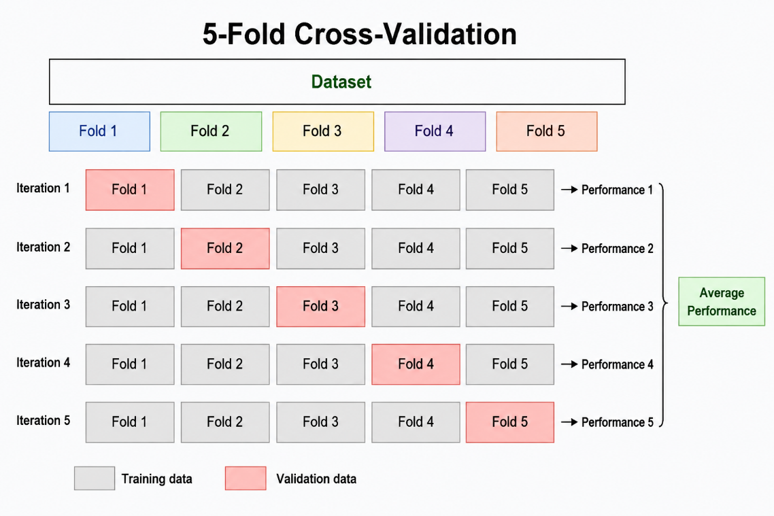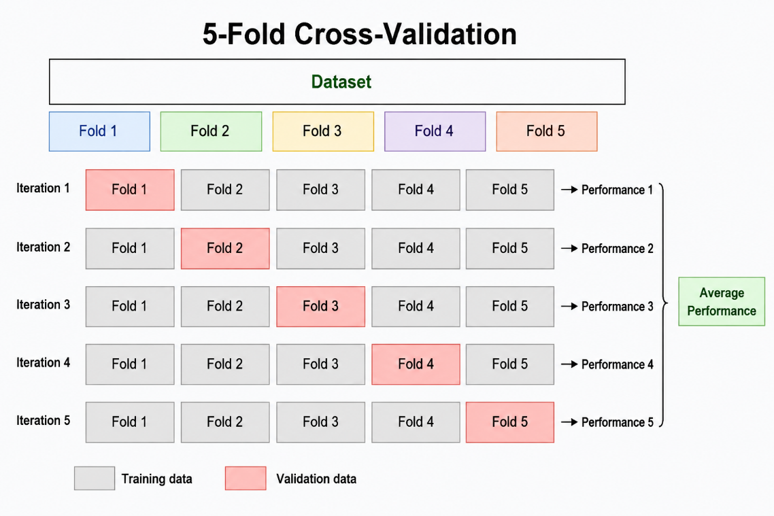


## 7. Interpret confusion matrices

A confusion matrix separates true positives, true negatives, false positives, and false negatives. Do not only ask which model has the highest accuracy; ask what kind of errors it makes.

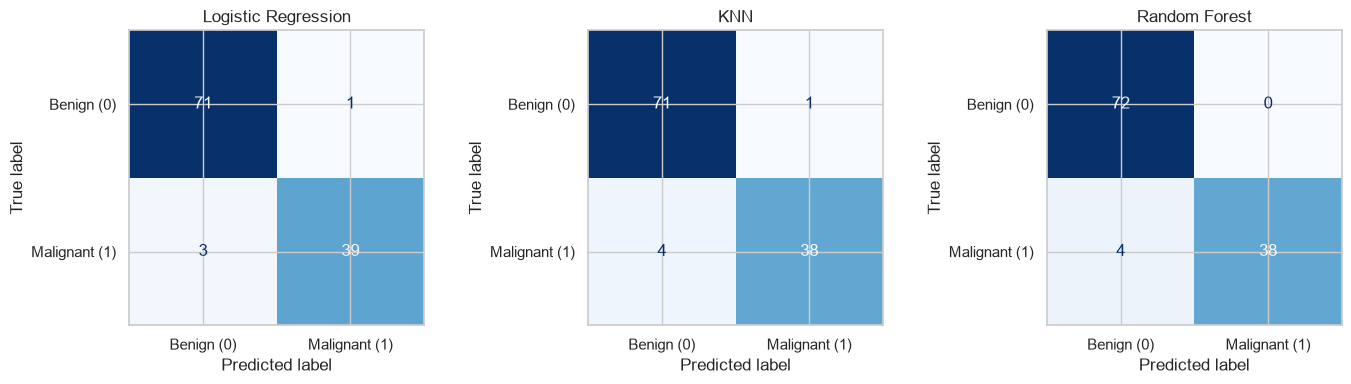

Logistic Regression specificity: 0.986
A false negative means malignant is predicted as benign, so recall is important here.


In [7]:
# A confusion matrix shows the types of correct and incorrect predictions.
# Rows are actual classes; columns are predicted classes.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["Benign (0)", "Malignant (1)"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

# For the positive class malignant:
# precision = TP / (TP + FP), recall/sensitivity = TP / (TP + FN)
tn, fp, fn, tp = confusion_matrix(y_test, predictions["Logistic Regression"]).ravel()
specificity = tn / (tn + fp)
print(f"Logistic Regression specificity: {specificity:.3f}")
print("A false negative means malignant is predicted as benign, so recall is important here.")


This section evaluates the three models using confusion matrices.
- Rows represent the actual class.
- Columns represent the predicted class.
- 0 = benign, 1 = malignant.
For Logistic Regression:
- 71 benign cases were correctly identified.
- 39 malignant cases were correctly identified.
- 1 false positive occurred.
- 3 malignant cases were missed, called false negatives.
- Specificity is 0.986, meaning it correctly identified 98.6% of benign cases.
KNN and Random Forest are also compared. Random Forest has no false positives, but it misses 4 malignant cases.

## 8. ROC curve and AUC

Class labels depend on a threshold, but models can also output probabilities. The ROC curve evaluates many thresholds. AUC measures how well the model ranks positive examples above negative examples.

ROC curve shows how a binary classifier performs at different probability thresholds.
- It plots Recall/True Positive Rate against False Positive Rate.
- It helps us see the trade-off between detecting more positive cases and creating more false alarms.
AUC means Area Under the ROC Curve.
- AUC summarizes the ROC curve as one value between 0 and 1.
- AUC close to 1 indicates strong classification performance.
- AUC close to 0.5 is similar to random guessing.
We use ROC and AUC when:
- The classification threshold may change.
- We want to compare different models.
- Accuracy alone does not show the complete performance.
- We need to understand the balance between missed positives and false alarms.

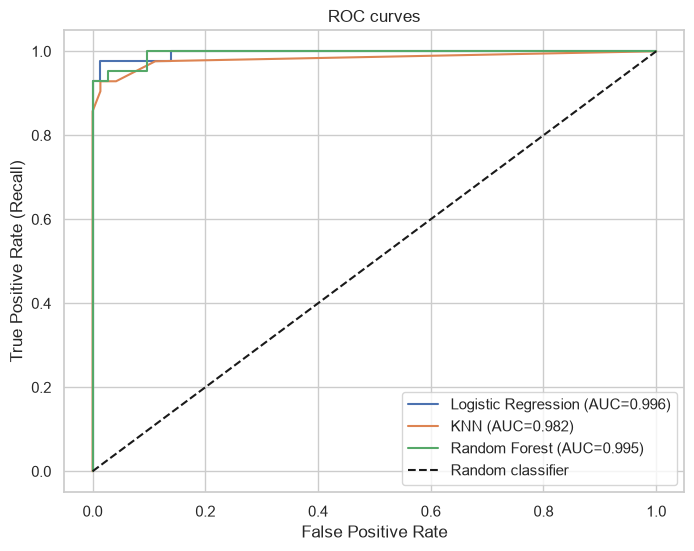

In [8]:
# ROC curves show the trade-off between true-positive rate and false-positive rate
# across many probability thresholds. AUC summarizes the ranking quality.
plt.figure(figsize=(8, 6))
for name, model in models.items():
    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curves")
plt.legend()
plt.show()


## 9. Decision thresholds

Changing the threshold changes the balance between recall and precision. In a medical screening setting, we may deliberately choose a lower threshold to reduce missed malignant cases, even if more benign cases are flagged for follow-up.

In [11]:
# The default threshold is usually 0.50, but the application may need more recall.
# Lowering the threshold identifies more possible malignant cases, but may create
# more false alarms. Students should try 0.30, 0.50, and 0.70 and compare metrics.
log_model = models["Logistic Regression"]
log_model.fit(X_train, y_train)
proba = log_model.predict_proba(X_test)[:, 1]

threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    y_threshold = (proba >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_threshold, zero_division=0),
        "Recall": recall_score(y_test, y_threshold, zero_division=0),
        "F1": f1_score(y_test, y_threshold, zero_division=0),
    })
display(pd.DataFrame(threshold_rows).round(3))


,Threshold,Precision,Recall,F1
0,0.3,0.976,0.976,0.976
1,0.5,0.975,0.929,0.951
2,0.7,1.000,0.905,0.950


This cell studies how changing the classification threshold affects performance.
- predict_proba() obtains the probability of being malignant.
- At threshold 0.30, more cases are classified as malignant, giving higher recall.
- At threshold 0.50, the default decision rule is used.
- At threshold 0.70, the model is more conservative, giving perfect precision but lower recall.
Results:
- Threshold 0.30: Precision = 0.976, Recall = 0.976
- Threshold 0.50: Precision = 0.975, Recall = 0.929
- Threshold 0.70: Precision = 1.000, Recall = 0.905
For medical screening, threshold 0.30 may be preferable because it misses fewer malignant cases.

## 10. Hyperparameter optimization

Hyperparameters are selected before model fitting. `GridSearchCV` evaluates a small set of KNN choices using cross-validation. The best setting is chosen using F1, which balances precision and recall. Students should explain why the best parameter is not necessarily the one with the best training score.

In [12]:
# Hyperparameters are choices made before training.
# GridSearchCV tests the combinations below using cross-validation.
knn_grid = GridSearchCV(
    models["KNN"],
    {"model__n_neighbors": [3, 5, 7, 11, 15],
     "model__weights": ["uniform", "distance"]},
    scoring="f1", cv=cv, n_jobs=-1
)
knn_grid.fit(X_train, y_train)
print("Best KNN parameters:", knn_grid.best_params_)
print("Best KNN cross-validated F1:", round(knn_grid.best_score_, 3))


Best KNN parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN cross-validated F1: 0.963


## 11. Examine classification errors

A useful model review asks which observations were misclassified and how confident the model was. The table below allows us to inspect errors rather than treating the final score as the whole story.

In [13]:
# Error analysis: inspect cases where the model was wrong.
error_table = X_test.copy()
error_table["actual"] = y_test
error_table["predicted"] = predictions["Logistic Regression"]
error_table["probability_malignant"] = proba
errors = error_table[error_table["actual"] != error_table["predicted"]]
print("Number of logistic-regression errors:", len(errors))
display(errors[["actual", "predicted", "probability_malignant"]].head(10))
print(classification_report(y_test, predictions["Logistic Regression"], target_names=["benign", "malignant"]))


Number of logistic-regression errors: 4


,actual,predicted,probability_malignant
455,0,1,0.509155
73,1,0,0.061429
190,1,0,0.314532
205,1,0,0.491610


              precision    recall  f1-score   support

      benign       0.96      0.99      0.97        72
   malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## Final discussion

The models used the same data but learned different decision rules, so their predictions are not identical. A good final model is selected by considering the application, the cost of errors, cross-validated performance, interpretability, and the behaviour of predictions on unseen data.

**Discussion question:** If missing a malignant case is much more costly than a false alarm, which metric and threshold would you prioritize?

# Extended classification concepts

This section adds the main theoretical points from the module and connects them to small, visual experiments. It also introduces an MNIST-style handwritten-digits example for multiclass classification.

## Classification decisions

Many classifiers first produce a score or probability for the positive class. A threshold converts that probability into a label:

- If $P(y=1|x) \ge t$, predict class 1.
- If $P(y=1|x) < t$, predict class 0.

The usual threshold is $t=0.5$, but the threshold should depend on the cost of false positives and false negatives.

## Decision boundaries

A decision boundary separates regions that receive different predicted labels. Logistic Regression usually creates a linear boundary, while KNN and tree-based models can create more flexible, nonlinear boundaries.

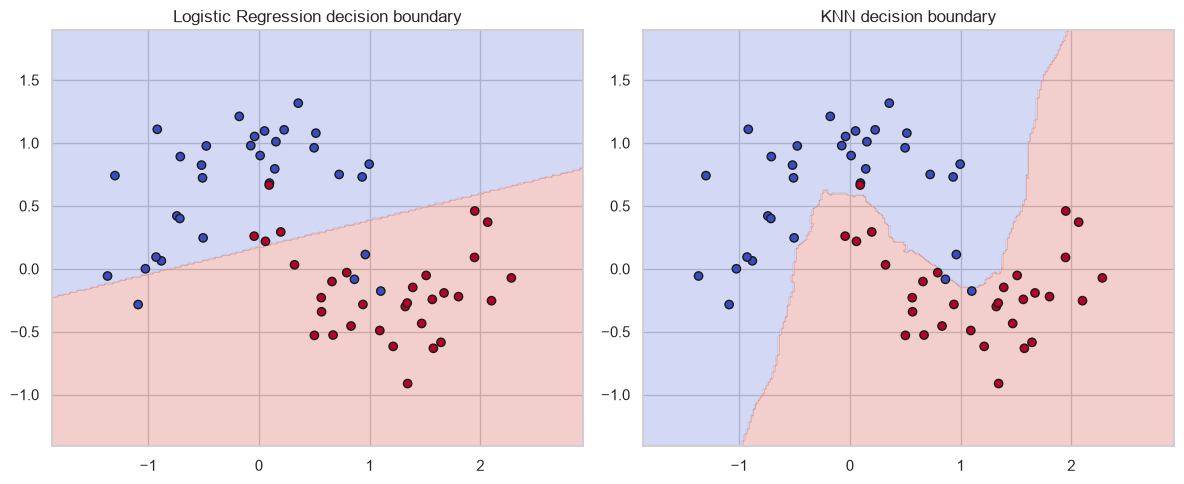

In [14]:
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression

X_moons, y_moons = make_moons(n_samples=250, noise=0.22, random_state=RANDOM_STATE)
X_moon_train, X_moon_test, y_moon_train, y_moon_test = train_test_split(
    X_moons, y_moons, test_size=0.25, stratify=y_moons, random_state=RANDOM_STATE
)

boundary_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(random_state=RANDOM_STATE))
    ]),
    "KNN": KNeighborsClassifier(n_neighbors=15)
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
xx, yy = np.meshgrid(
    np.linspace(X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5, 250),
    np.linspace(X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5, 250)
)
for ax, (name, model) in zip(axes, boundary_models.items()):
    model.fit(X_moon_train, y_moon_train)
    grid_pred = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, grid_pred, alpha=0.25, cmap="coolwarm")
    ax.scatter(X_moon_test[:, 0], X_moon_test[:, 1], c=y_moon_test, cmap="coolwarm", edgecolor="k")
    ax.set_title(name + " decision boundary")
plt.tight_layout()
plt.show()

The two models use the same observations but create different decision regions. This is why model choice can change predictions even when the dataset is unchanged.

## Challenges in binary classification

Common challenges include imbalanced classes, noisy observations, overlapping classes, missing values, changing data distributions, and overfitting. Accuracy can be misleading when one class is much more common than the other.

In [15]:
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier

# A deliberately imbalanced example: only 5% of cases are positive.
X_imb, y_imb = make_classification(
    n_samples=1000, n_features=8, weights=[0.95, 0.05],
    random_state=RANDOM_STATE
)
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_imb, y_imb)
y_dummy = dummy.predict(X_imb)
print("Positive-class proportion:", y_imb.mean().round(3))
print("Dummy accuracy:", round(accuracy_score(y_imb, y_dummy), 3))
print("Dummy recall:", round(recall_score(y_imb, y_dummy, zero_division=0), 3))
print("A high accuracy can hide the fact that the model detects no positive cases.")

Positive-class proportion: 0.057
Dummy accuracy: 0.943
Dummy recall: 0.0
A high accuracy can hide the fact that the model detects no positive cases.


## Metric formulations

For a binary classifier, let TP be true positives, TN true negatives, FP false positives, and FN false negatives.

- **Accuracy** = $(TP + TN)/(TP + TN + FP + FN)$
- **Precision** = $TP/(TP + FP)$
- **Recall / sensitivity / TPR** = $TP/(TP + FN)$
- **Specificity / TNR** = $TN/(TN + FP)$
- **False-positive rate** = $FP/(FP + TN) = 1 - specificity$
- **F1 score** = $2 \times (precision \times recall)/(precision + recall)$

Precision focuses on the correctness of positive predictions. Recall focuses on finding the actual positive cases. F1 balances both.

## MNIST-style multiclass classification

The next dataset contains handwritten digits from 0 to 9. Unlike the breast-cancer example, this is a **multiclass** problem: each image belongs to one of ten classes. The same evaluation ideas still apply, but confusion matrices become 10 by 10 and metrics are often reported using macro or weighted averages.

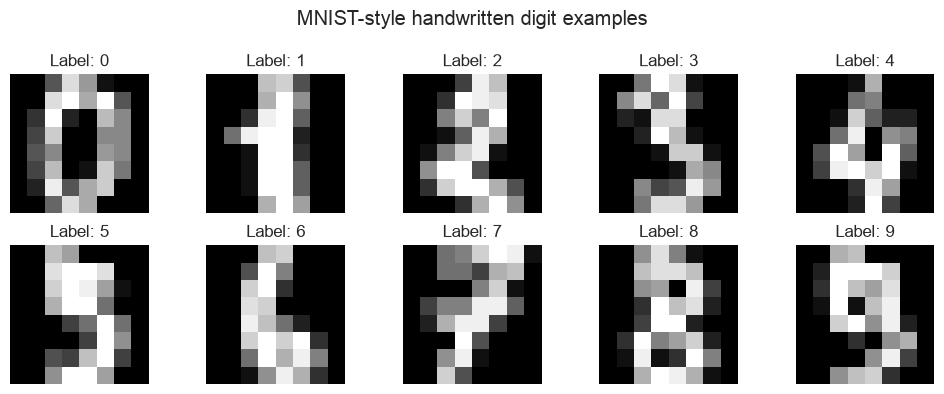

Multiclass accuracy: 0.972
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.89      0.89      0.89        36
           2       1.00      1.00      1.00        35
           3       0.97      1.00      0.99        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.89      0.89      0.89        35
           9       1.00      0.97      0.99        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



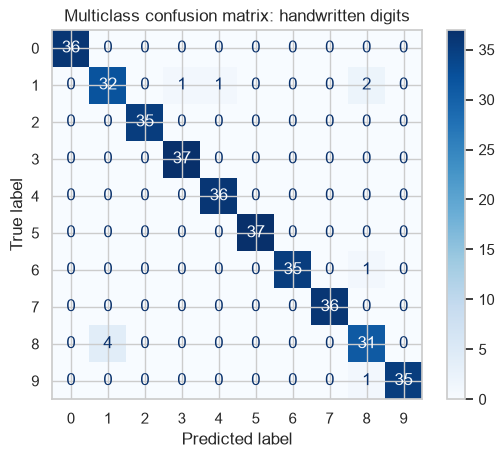

In [20]:
from sklearn.datasets import load_digits
from sklearn.metrics import ConfusionMatrixDisplay

digits = load_digits()
X_digits, y_digits = digits.data, digits.target
X_dtrain, X_dtest, y_dtrain, y_dtest = train_test_split(
    X_digits, y_digits, test_size=0.20, stratify=y_digits, random_state=RANDOM_STATE
)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), digits.images[:10], y_digits[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.suptitle("MNIST-style handwritten digit examples")
plt.tight_layout()
plt.show()

digit_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
digit_model.fit(X_dtrain, y_dtrain)
digit_pred = digit_model.predict(X_dtest)
print("Multiclass accuracy:", round(accuracy_score(y_dtest, digit_pred), 3))
print(classification_report(y_dtest, digit_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_dtest, digit_pred, cmap="Blues", values_format="d")
plt.title("Multiclass confusion matrix: handwritten digits")
plt.show()

For multiclass classification, a class may be confused with a particular other class. For example, the matrix can show whether 3 is often predicted as 8. This is more useful than one overall accuracy value when some classes are difficult.

## Error analysis

Error analysis means examining incorrect predictions, not only reporting a metric. Useful questions include:

- Which classes are confused most often?
- Are errors concentrated in a particular group or feature range?
- Is the model uncertain, or confidently wrong?
- Would more data, better features, a different threshold, or another algorithm help?

In [21]:
# Inspect the most uncertain logistic-regression predictions.
error_review = X_test.copy()
error_review["actual"] = y_test
error_review["predicted"] = predictions["Logistic Regression"]
error_review["p_malignant"] = proba
error_review["confidence"] = np.maximum(error_review["p_malignant"], 1 - error_review["p_malignant"])
error_review = error_review[error_review["actual"] != error_review["predicted"]]
display(error_review.sort_values("confidence").head(10)[["actual", "predicted", "p_malignant", "confidence"]])

,actual,predicted,p_malignant,confidence
205,1,0,0.491610,0.508390
455,0,1,0.509155,0.509155
190,1,0,0.314532,0.685468
73,1,0,0.061429,0.938571


## Multilabel and multioutput classification

- In **multilabel classification**, one sample can have several labels.
- In **multioutput classification**, the model predicts several target columns.

The code below creates a small demonstration of both ideas. It is separate from the breast-cancer target, which is binary.

In [24]:
from sklearn.datasets import make_multilabel_classification
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import MultiOutputClassifier

# Multilabel: each row can have more than one label equal to 1.
X_multi, y_multi = make_multilabel_classification(
    n_samples=300, n_features=8, n_classes=3, n_labels=2, random_state=RANDOM_STATE
)
multi_model = OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
multi_model.fit(X_multi, y_multi)
print("Multilabel target shape:", y_multi.shape)
print("One example's labels:", y_multi[0])
print("Predicted labels for one example:", multi_model.predict(X_multi[:1])[0])

# Multioutput: predict two binary targets together.
y_output = np.column_stack([y_multi[:, 0], y_multi[:, 1]])
multioutput_model = MultiOutputClassifier(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
multioutput_model.fit(X_multi, y_output)
print("Multioutput prediction shape:", multioutput_model.predict(X_multi[:5]).shape)

Multilabel target shape: (300, 3)
One example's labels: [1 1 0]
Predicted labels for one example: [1 1 0]
Multioutput prediction shape: (5, 2)


## Extended summary

Classification is not only about maximizing accuracy. We must define the positive class, understand the decision threshold, select metrics that reflect the application, use cross-validation, inspect the confusion matrix and ROC/AUC, compare models, and investigate errors. Binary, multiclass, multilabel, and multioutput problems require related but different evaluation strategies.